# Exploration des données SkillCorner

Ce notebook présente les statistiques de passes, de courses sans ballon et d'activité physique des équipes d'A-League 2024-2025, avec un focus sur Auckland FC. Il prépare notre étude de la zone 14.

## 1. Importation et préparation des données
Les fichiers Parquet sont lus depuis le stockage S3 d'Onyxia avec `s3fs` et `pd.read_parquet()`. Les trois tables ont des objets différents : `passing` pour les passes, `obr` pour les courses sans ballon (*off-ball runs*) et `physical` pour l'activité physique. On garde leurs noms d'origine lors de l'importation pour pouvoir retrouver les variables SkillCorner et vérifier leur définition. 

In [137]:
import s3fs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

obr = pd.read_parquet("s3://lfaivre/diffusion/aus1league_obraggregates_20242025.parquet", filesystem=fs)
passing = pd.read_parquet("s3://lfaivre/diffusion/aus1league_passingaggregates_20242025.parquet", filesystem=fs)
physical = pd.read_parquet("s3://lfaivre/diffusion/aus1league_physicalaggregates_20242025.parquet", filesystem=fs)

### Filtrage selon le nombre de matchs

On applique le même seuil minimal de trois matchs aux trois tables afin d'écarter les observations reposant sur une exposition particulièrement faible. Les colonnes de référence diffèrent selon les fichiers : `count_match` pour les statistiques physiques et `performance_count` pour les passes et les courses. On utilise `.copy()` pour travailler avec des copies indépendantes de la table d'origine.

In [ ]:
#on garde uniquement les joueurs à plus de 3 matchs 
MIN_MATCHES = 3

#on applique le filtre sur les 3 data frames et on en fait une copie 
phys = physical.loc[physical['count_match'] >= MIN_MATCHES].copy()
pas = passing.loc[passing['performance_count'] >= MIN_MATCHES].copy()
courses = obr.loc[obr['performance_count'] >= MIN_MATCHES].copy()

print(physical[['team_name', 'count_match']].head())
print(passing[['team_name', 'performance_count']].head())
print(obr[['team_name', 'performance_count']].head())

                         team_name  count_match
0        Perth Glory Football Club           24
1  Melbourne Victory Football Club            6
2                     Macarthur FC            8
3             Sydney Football Club            4
4             Sydney Football Club            1
                         team_name  performance_count
0        Perth Glory Football Club                 13
1  Melbourne Victory Football Club                  2
2                     Macarthur FC                  7
3             Sydney Football Club                  4
4             Sydney Football Club                  1
                         team_name  performance_count
0        Perth Glory Football Club                 13
1  Melbourne Victory Football Club                  2
2                     Macarthur FC                  7
3             Sydney Football Club                  4
4             Sydney Football Club                  1


### Harmonisation des noms d'équipes

On crée la colonne `equipe` à partir de `team_name` en retirant les suffixes comme « FC » ou « Football Club ». L'objectif est d'obtenir des noms identiques dans les trois fichiers, pour que les agrégations et les jointures par équipe ne créent pas de doublons artificiels. La colonne originale est conservée, `.map()` applique la transformation à chaque nom.

In [139]:
for df in [phys, pas, courses]:
    df['equipe'] = df['team_name'].map(
        lambda s: s.replace(' Football Club', '').replace(' FC', '').strip()
    )


## 2. Calcul des moyennes pondérées

Les données saisonnières sont organisées au niveau des joueurs. Pour construire un profil descriptif par équipe, on calcule donc des moyennes de leurs indicateurs. Une moyenne simple donnerait le même poids à un joueur peu observé et à un joueur très utilisé. Nous retenons donc des poids adaptés à la nature de chaque variable. Les moyennes ainsi obtenues sont des agrégats reconstruits à partir des profils des joueurs, et non des statistiques d'équipe directement fournies par SkillCorner.

In [140]:
#Statistiques physiques : temps total de jeu
phys['poids'] = phys['minutes_full_all'] * phys['count_match']
#Statistiques physiques : temps en possession
phys['poids_tip'] = phys['minutes_full_tip'] * phys['count_match']
#Statistiques physiques : temps hors possession
phys['poids_otip'] = phys['minutes_full_otip'] * phys['count_match']
#Passes et courses : temps de possession
pas['poids'] = pas['minutes_tip'] * pas['performance_count']
courses['poids'] = courses['minutes_tip'] * courses['performance_count']
#Qualité des passes : nombre de passes tentées
pas['poids_passes'] = pas['pass_count_attempted_total']
#Distance moyenne des courses : nombre de courses
courses['poids_courses'] = courses['offballrun_count_total']

### Fonctions d'agrégation

`moyenne_ponderee_par_equipe()` applique, pour chaque indicateur, la formule `somme(valeur × poids) / somme(poids)`, après regroupement par `equipe` avec `groupby()`. `fillna(0)` facilite le calcul des produits, tandis que le masque utilisant `isna()` annule aussi le poids d'une observation dont la valeur manque, ainsi elle ne contribue ni au numérateur ni au dénominateur. Un dénominateur nul donnera une valeur manquante. `dispersion_profils()` calcule séparément médiane, écart-type, minimum et maximum des valeurs individuelles, pour décrire leur dispersion au sein des équipes.



In [141]:
#moyenne pondérée = somme(variable * poids)/somme(poids)
def moyenne_ponderee_par_equipe(df, variables, poids):
    resultat = {}

    for variable in variables:
        valeurs = df[variable].fillna(0) #on gere les valeurs manquantes, on met 0 au lieu de NA ce qui va nous permettre de calculer la somme
        poids_valides = df[poids].fillna(0)
        poids_valides = poids_valides.where(df[variable].notna(), 0) #permet d'exclure les valeurs manquantes de la moyenne pondérée (donne poids*1 lorsque la valeur est là, 0 sinon)
        numerateur = (valeurs * poids_valides).groupby(df['equipe']).sum()
        denominateur = poids_valides.groupby(df['equipe']).sum()
        resultat[variable] = numerateur / denominateur
    return pd.DataFrame(resultat)

#fonction qui permet d'avoir la dispersion des profils de joueurs au sein des équipes
def dispersion_profils(df, variables):
    dispersion = df.groupby('equipe').agg({v: ['median', 'std', 'min', 'max'] for v in variables})
    return dispersion

## 3. Choix et préparation des indicateurs

Les variables sont regroupées dans plusieurs listes pour appliquer les mêmes traitements à une famille d'indicateurs sans recopier les instructions. Le suffixe `p30tip` renvoie à un volume rapporté à 30 minutes de possession (*time in possession*), il ne faut donc pas le confondre avec un total brut par match. On sépare les volumes de passes, leur qualité, les courses sans ballon et les mesures physiques, car les unités et les pondérations pertinentes ne sont pas les mêmes.

In [142]:
#passes :
variables_passes = [
    'pass_count_attempted_p30tip',            #Passes tentees
    'pass_count_completed_p30tip',            #Passes reussies
    'pass_count_linebreak_attempted_p30tip',  #Passes qui cassent une ligne
    'pass_count_linebreak_completed_p30tip',  #Passes reussies qui cassent une ligne
    'pass_count_difficultpass_attempted_p30tip', #Passes difficiles
    'pass_count_longrange_attempted_p30tip',  #Passes longues
    'pass_count_dangerous_attempted_p30tip',  #Passes dangereuses
    'pass_count_shotwithin10s_p30tip'         #Passes suivies d'un tir sous 10 s
]
variables_qualite = [
    'pass_pct_completed',                     #Taux de passes reussies
    'pass_avgdistance'                        #Distance moyenne des passes
]

#courses :
variables_courses = [
    'offballrun_count_p30tip',                #Toutes les courses sans ballon
    'offballrun_count_dangerous_p30tip',      #Courses dangereuses
    'offballrun_count_targeted_p30tip',       #Courses visees par une passe
    'offballrun_count_received_p30tip',       #Courses avec reception
    'offballrun_count_penaltyarea_p30tip',    #Courses dans la surface
    'offballrun_count_abovehsr_p30tip'        #Courses au-dessus du seuil HSR
]

#Statistiques physiques : ensemble du temps de jeu
variables_physiques = [
    'total_metersperminute_full_all',
    'hsr_distance_full_all'
]

#Statistiques physiques : en possession du ballon
variables_physiques_tip = [
    'total_metersperminute_full_tip'
]
#Statistiques physiques : hors possession du ballon
variables_physiques_otip = [
    'total_metersperminute_full_otip'
]

### Construction du tableau commun aux équipes

Chaque famille d'indicateurs est agrégée avec son poids : minutes en possession pour les volumes normalisés de passes et de courses, nombre de passes tentées pour les mesures de qualité, nombre de courses pour leur distance moyenne, et minutes de jeu adaptées à la phase de possession pour l'activité physique. `reset_index()` transforme `equipe` en colonne pour effectuer les `merge()`, `how='outer'` permet de conserver toutes les équipes présentes dans au moins une table. On calcule ensuite des proportions en divisant deux variables.


In [143]:
#calcul des moyennes pondérées par équipes
tab_passes = moyenne_ponderee_par_equipe(pas, variables_passes, 'poids')
tab_qualite = moyenne_ponderee_par_equipe(pas, variables_qualite, 'poids_passes')
tab_courses = moyenne_ponderee_par_equipe(courses, variables_courses, 'poids')
#Distance moyenne des courses sans ballon
tab_distance_courses = moyenne_ponderee_par_equipe(courses, ['offballrun_avgdistance'], 'poids_courses')
tab_physique = moyenne_ponderee_par_equipe(phys, variables_physiques, 'poids')
tab_physique_tip = moyenne_ponderee_par_equipe(phys, variables_physiques_tip, 'poids_tip')
tab_physique_otip = moyenne_ponderee_par_equipe(phys, variables_physiques_otip, 'poids_otip')

#Types de courses susceptibles d'eclairer le contournement de la zone 14
variables_types = [
    'behindrun_count_p30tip',                 #Courses dans le dos de la defense
    'comingshortrun_count_p30tip',            #Courses en venant court
    'supportrun_count_p30tip',                #Courses de soutien
    'pullingwiderun_count_p30tip',            #Courses ecartant sur l'aile
    'pullinghalfspacerun_count_p30tip'        #Courses vers les demi-espaces
]
tab_types = moyenne_ponderee_par_equipe(courses, variables_types, 'poids') 

#on fusionne les tableaux de moyennes pondérées
equipes = tab_passes.reset_index()
for tableau in [tab_qualite, tab_courses, tab_physique, tab_types, tab_physique_tip, tab_physique_otip, tab_distance_courses]:
    equipes = equipes.merge(tableau.reset_index(), on='equipe', how='outer')

#proportions de passes longues et passes cassant des lignes parmi les passes tentées; courses dangereuses, courses dans le dos de la défense, courses en solution courte parmi les courses
equipes['part_passes_longues'] = (equipes['pass_count_longrange_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
equipes['part_passes_lignes'] = (equipes['pass_count_linebreak_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
#proportion de passes cassant les lignes qui sont réussies
equipes['reussite_passes_lignes'] = (equipes['pass_count_linebreak_completed_p30tip'] / equipes['pass_count_linebreak_attempted_p30tip'])
#proportion de passes difficiles parmi les passes tentées
equipes['part_passes_difficiles'] = (equipes['pass_count_difficultpass_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
equipes['part_courses_dangereuses'] = (equipes['offballrun_count_dangerous_p30tip'] / equipes['offballrun_count_p30tip'])
equipes['part_courses_dos_defense'] = (equipes['behindrun_count_p30tip'] / equipes['offballrun_count_p30tip'])
equipes['part_courses_courtes'] = (equipes['comingshortrun_count_p30tip'] / equipes['offballrun_count_p30tip'])

### Traduction des noms des variables uniquement pour l'affichage

Les colonnes originales ont des noms techniques SkillCorner, utiles pour le calcul mais peu lisibles à l'affichage. Le dictionnaire `noms_variables` associe à chaque nom d'origine un libellé français et, lorsque c'est nécessaire, une unité. On utilise ensuite `.rename(columns=noms_variables)` sur les tableaux affichés, sans modifier les noms des colonnes du DataFrame de travail `equipes` : les calculs suivants continuent ainsi d'employer les noms d'origine.

In [144]:
noms_variables = {
    'pass_count_attempted_p30tip': 'Passes tentées / 30 min',
    'pass_count_completed_p30tip': 'Passes réussies / 30 min',
    'pass_count_linebreak_attempted_p30tip': 'Passes cassant une ligne / 30 min',
    'pass_count_linebreak_completed_p30tip': 'Passes cassant une ligne réussies / 30 min',
    'pass_count_difficultpass_attempted_p30tip': 'Passes difficiles / 30 min',
    'pass_count_longrange_attempted_p30tip': 'Passes longues / 30 min',
    'pass_count_dangerous_attempted_p30tip': 'Passes dangereuses / 30 min',
    'pass_count_shotwithin10s_p30tip': 'Passes suivies d’un tir / 30 min',
    'pass_pct_completed': 'Taux de passes réussies',
    'pass_avgdistance': 'Distance moyenne des passes (m)',
    'offballrun_count_p30tip': 'Courses / 30 min',
    'offballrun_count_dangerous_p30tip': 'Courses dangereuses / 30 min',
    'offballrun_count_targeted_p30tip': 'Courses ciblées par une passe / 30 min',
    'offballrun_count_received_p30tip': 'Courses avec réception / 30 min',
    'offballrun_count_penaltyarea_p30tip': 'Courses dans la surface / 30 min',
    'offballrun_count_abovehsr_p30tip': 'Courses à haute vitesse / 30 min',
    'behindrun_count_p30tip': 'Courses dans le dos / 30 min',
    'comingshortrun_count_p30tip': 'Courses en venant court / 30 min',
    'supportrun_count_p30tip': 'Courses de soutien / 30 min',
    'pullingwiderun_count_p30tip': 'Courses vers l’aile / 30 min',
    'pullinghalfspacerun_count_p30tip': 'Courses vers les demi-espaces / 30 min',
    'offballrun_avgdistance': 'Distance moyenne des courses (m)',
    'total_metersperminute_full_all': 'Mètres parcourus / min',
    'total_metersperminute_full_tip': 'Mètres / min en possession',
    'total_metersperminute_full_otip': 'Mètres / min hors possession',
    'hsr_distance_full_all': 'Distance à haute vitesse (unité SkillCorner)',
    'part_passes_longues': 'Part de passes longues',
    'part_passes_lignes': 'Part de passes cassant une ligne',
    'reussite_passes_lignes': 'Réussite des passes cassant une ligne',
    'part_passes_difficiles': 'Part de passes difficiles',
    'part_courses_dangereuses': 'Part de courses dangereuses',
    'part_courses_dos_defense': 'Part de courses dans le dos',
    'part_courses_courtes': 'Part de courses en venant court'
}

## 4. Tableaux descriptifs par équipe

Les cellules suivantes présentent successivement les volumes de passes, leurs caractéristiques, les courses sans ballon et les mesures physiques. Les sélections `equipes[['equipe'] + variables_...]` conservent uniquement les colonnes utiles pour chaque tableau , `.round(2)` améliore la lisibilité sans changer les valeurs enregistrées dans `equipes`. 

In [145]:
#on affiche les statistiques de passes par équipe
print('PASSES — VOLUME PAR 30 MINUTES DE POSSESSION')
equipes[['equipe'] + variables_passes].rename(columns=noms_variables).round(2)


PASSES — VOLUME PAR 30 MINUTES DE POSSESSION


,equipe,Passes tentées / 30 min,Passes réussies / 30 min,Passes cassant une ligne / 30 min,Passes cassant une ligne réussies / 30 min,Passes difficiles / 30 min,Passes longues / 30 min,Passes dangereuses / 30 min,Passes suivies d’un tir / 30 min
0,Adelaide United,44.69,37.63,7.65,5.64,6.62,2.44,3.52,1.71
1,Auckland,39.98,32.37,6.07,4.24,8.14,2.36,3.84,1.90
2,Brisbane Roar,43.24,36.71,7.27,5.19,6.17,2.57,3.33,1.85
3,Central Coast Mariners,41.63,35.24,7.28,5.35,5.94,2.91,2.70,1.34
4,Macarthur,42.84,35.47,7.20,5.24,7.47,2.95,4.10,1.83
5,Melbourne City,42.98,36.96,6.88,5.17,6.23,3.27,3.82,2.13
6,Melbourne Victory,40.67,34.28,6.74,4.97,7.02,2.76,4.27,2.56
7,Newcastle United Jets,44.81,39.20,6.52,5.10,5.77,2.77,3.29,1.73
8,Perth Glory,42.06,33.71,7.11,4.62,7.58,2.94,3.59,1.78
9,Sydney,44.12,38.18,6.96,5.60,6.41,2.17,3.85,2.49


In [146]:
print('PASSES — QUALITÉ ET DISTANCE')
equipes[['equipe'] + variables_qualite].rename(columns=noms_variables).round(2)

PASSES — QUALITÉ ET DISTANCE


,equipe,Taux de passes réussies,Distance moyenne des passes (m)
0,Adelaide United,84.08,16.38
1,Auckland,80.96,16.17
2,Brisbane Roar,84.89,16.53
3,Central Coast Mariners,84.78,16.95
4,Macarthur,82.81,16.82
5,Melbourne City,86.00,17.30
6,Melbourne Victory,84.28,16.50
7,Newcastle United Jets,87.47,16.91
8,Perth Glory,80.16,17.03
9,Sydney,86.58,15.14


In [147]:
#on affiche les proportions en pourcentage
variables_proportions_passes = [
    'part_passes_longues', 'part_passes_lignes',
    'reussite_passes_lignes', 'part_passes_difficiles'
]
tableau_parts_passes = equipes[['equipe'] + variables_proportions_passes].copy()
tableau_parts_passes[variables_proportions_passes] = tableau_parts_passes[variables_proportions_passes] * 100
print('PASSES — PROPORTIONS EN %')
tableau_parts_passes.rename(columns=noms_variables).round(2)

PASSES — PROPORTIONS EN %


,equipe,Part de passes longues,Part de passes cassant une ligne,Réussite des passes cassant une ligne,Part de passes difficiles
0,Adelaide United,5.45,17.11,73.79,14.80
1,Auckland,5.89,15.18,69.79,20.35
2,Brisbane Roar,5.95,16.80,71.47,14.27
3,Central Coast Mariners,6.99,17.49,73.53,14.27
4,Macarthur,6.88,16.81,72.68,17.43
5,Melbourne City,7.62,16.00,75.18,14.50
6,Melbourne Victory,6.78,16.58,73.75,17.26
7,Newcastle United Jets,6.18,14.56,78.19,12.87
8,Perth Glory,6.98,16.91,65.03,18.03
9,Sydney,4.92,15.77,80.51,14.53


### Méthode de lecture — tableaux de passes

Les tableaux distinguent les taux par 30 minutes de possession des mesures de qualité telles que le taux de réussite ou la distance moyenne. Les proportions calculées initialement entre 0 et 1 sont affichées en pourcentages. Le DataFrame `equipes` conserve ses proportions d'origine pour les calculs et les graphiques ultérieurs. Les intitulés français définis précédemment sont appliqués au moment de l'affichage.

### Tableaux des courses sans ballon

On applique le même principe de sélection des colonnes aux volumes, aux types de courses et à leur distance moyenne. 

In [148]:
#on affiche les statistiques sur les courses
print('COURSES SANS BALLON — VOLUME PAR 30 MINUTES DE POSSESSION')
equipes[['equipe'] + variables_courses].rename(columns=noms_variables).round(2)

COURSES SANS BALLON — VOLUME PAR 30 MINUTES DE POSSESSION


,equipe,Courses / 30 min,Courses dangereuses / 30 min,Courses ciblées par une passe / 30 min,Courses avec réception / 30 min,Courses dans la surface / 30 min,Courses à haute vitesse / 30 min
0,Adelaide United,21.84,7.32,7.68,5.83,3.76,5.30
1,Auckland,24.24,6.71,8.53,6.67,3.29,6.09
2,Brisbane Roar,20.99,5.64,7.23,6.14,2.46,4.01
3,Central Coast Mariners,20.79,4.47,7.12,6.07,2.08,4.14
4,Macarthur,20.69,5.48,7.58,6.01,2.56,5.21
5,Melbourne City,23.71,6.81,8.19,6.69,3.09,5.17
6,Melbourne Victory,22.96,7.49,8.02,6.41,3.16,5.44
7,Newcastle United Jets,22.57,6.12,7.76,6.27,2.88,4.91
8,Perth Glory,21.67,6.54,7.63,5.70,2.54,4.72
9,Sydney,21.96,6.12,7.83,6.37,2.70,4.67


In [149]:
print('COURSES SANS BALLON — TYPES DE COURSES')
equipes[['equipe'] + variables_types].rename(columns=noms_variables).round(2)

COURSES SANS BALLON — TYPES DE COURSES


,equipe,Courses dans le dos / 30 min,Courses en venant court / 30 min,Courses de soutien / 30 min,Courses vers l’aile / 30 min,Courses vers les demi-espaces / 30 min
0,Adelaide United,1.68,2.56,3.46,1.12,0.48
1,Auckland,1.42,2.82,4.53,1.55,0.96
2,Brisbane Roar,1.14,2.99,3.94,1.31,0.52
3,Central Coast Mariners,1.10,3.49,3.97,1.20,0.40
4,Macarthur,1.35,2.39,3.76,1.57,0.42
5,Melbourne City,1.45,2.83,3.68,1.55,0.49
6,Melbourne Victory,1.51,2.49,4.78,1.48,0.72
7,Newcastle United Jets,1.45,3.69,3.63,1.38,0.52
8,Perth Glory,1.84,2.97,3.75,1.26,0.51
9,Sydney,1.92,2.92,4.18,1.10,0.49


In [150]:
#on affiche les proportions en pourcentage
variables_proportions_courses = [
    'part_courses_dangereuses', 'part_courses_dos_defense', 'part_courses_courtes'
]
tableau_parts_courses = equipes[['equipe'] + variables_proportions_courses].copy()
tableau_parts_courses[variables_proportions_courses] = tableau_parts_courses[variables_proportions_courses] * 100
print('COURSES SANS BALLON — PROPORTIONS EN %')
tableau_parts_courses.rename(columns=noms_variables).round(2)

COURSES SANS BALLON — PROPORTIONS EN %


,equipe,Part de courses dangereuses,Part de courses dans le dos,Part de courses en venant court
0,Adelaide United,33.53,7.69,11.74
1,Auckland,27.68,5.85,11.63
2,Brisbane Roar,26.89,5.43,14.24
3,Central Coast Mariners,21.51,5.30,16.76
4,Macarthur,26.50,6.53,11.56
5,Melbourne City,28.72,6.13,11.94
6,Melbourne Victory,32.62,6.58,10.84
7,Newcastle United Jets,27.12,6.41,16.33
8,Perth Glory,30.16,8.48,13.72
9,Sydney,27.88,8.72,13.29


In [151]:
print('COURSES SANS BALLON — DISTANCE MOYENNE')
equipes[['equipe', 'offballrun_avgdistance']].rename(columns=noms_variables).round(2)

COURSES SANS BALLON — DISTANCE MOYENNE


,equipe,Distance moyenne des courses (m)
0,Adelaide United,13.47
1,Auckland,13.94
2,Brisbane Roar,12.63
3,Central Coast Mariners,12.87
4,Macarthur,14.06
5,Melbourne City,13.10
6,Melbourne Victory,13.49
7,Newcastle United Jets,13.23
8,Perth Glory,13.27
9,Sydney,12.68


### Méthode de lecture — tableaux de courses

Les volumes de courses sont exprimés par 30 minutes de possession, alors que `offballrun_avgdistance` est une distance moyenne en mètres. Les parts de courses sont des rapports entre deux taux construits sur la même base, elles sont converties en pourcentage uniquement dans le tableau d'affichage. 

### Tableau des mesures physiques

On distingue l'activité sur tout le temps de jeu, en possession et hors possession, car ces indicateurs reposent sur des temps d'exposition différents. 

In [152]:
#on affiche les statistiques physiques
print('ACTIVITÉ PHYSIQUE — COMPARAISON DES ÉQUIPES')
equipes[['equipe'] + variables_physiques + variables_physiques_tip + variables_physiques_otip].rename(columns=noms_variables).round(2)

ACTIVITÉ PHYSIQUE — COMPARAISON DES ÉQUIPES


,equipe,Mètres parcourus / min,Distance à haute vitesse (unité SkillCorner),Mètres / min en possession,Mètres / min hors possession
0,Adelaide United,115.56,531.04,141.14,154.95
1,Auckland,112.69,605.31,143.97,156.55
2,Brisbane Roar,117.18,491.27,141.18,154.22
3,Central Coast Mariners,113.73,492.30,135.84,148.92
4,Macarthur,109.05,479.81,137.45,141.34
5,Melbourne City,117.26,567.89,141.16,161.60
6,Melbourne Victory,110.74,526.82,140.62,151.99
7,Newcastle United Jets,115.84,575.01,140.23,149.83
8,Perth Glory,115.45,524.01,143.69,150.69
9,Sydney,112.87,586.79,135.82,165.21


## 5. Focus sur Auckland FC

On sélectionne une liste restreinte d'`variables_clefs` pour éviter de dupliquer toutes les colonnes des tableaux précédents. Le résumé calcule pour chaque indicateur sa moyenne, sa médiane, son écart-type et ses bornes entre les treize équipes présentes dans `equipes`. Ces statistiques décrivent la distribution des profils agrégés des équipes. Elles ne correspondent pas à une moyenne de tous les joueurs du championnat.


In [153]:
#on conserve les indicateurs principaux pour une comparaison synthétique
variables_clefs = [
    'pass_count_attempted_p30tip',
    'pass_count_linebreak_attempted_p30tip',
    'pass_count_difficultpass_attempted_p30tip',
    'pass_avgdistance',
    'offballrun_count_p30tip',
    'offballrun_count_dangerous_p30tip',
    'part_passes_longues',
    'part_courses_dos_defense',
    'reussite_passes_lignes',
    'part_passes_difficiles',
    'offballrun_avgdistance'
]

#on construit le résumé avec les statistiques vues dans le cours
lignes_resume = []
for variable in variables_clefs:
    lignes_resume.append({
        'Indicateur': noms_variables[variable],
        'Moyenne': equipes[variable].mean(),
        'Médiane': equipes[variable].median(),
        'Écart-type': equipes[variable].std(),
        'Minimum': equipes[variable].min(),
        'Maximum': equipes[variable].max()
    })
resume_ligue = pd.DataFrame(lignes_resume)

### Extraction d'Auckland et formatage des résultats

Le filtre `.loc[equipes['equipe'] == 'Auckland']` extrait la ligne de l'équipe et `.iloc[0]` récupère la valeur de chaque indicateur. Une liste de dictionnaires permet de construire directement un tableau « une ligne par indicateur ». Les proportions sont multipliées par 100 uniquement dans les tableaux présentés, pour les exprimer en points de pourcentage.


In [154]:
#on sélectionne Auckland
auckland = equipes.loc[equipes['equipe'] == 'Auckland'].copy()

#on construit directement un tableau avec les noms des indicateurs
lignes_portrait = []
for variable in variables_clefs:
    valeur = auckland[variable].iloc[0]
    nom = noms_variables[variable]

    #on convertit les proportions en pourcentage
    if variable.startswith('part_') or variable == 'reussite_passes_lignes':
        valeur = valeur * 100
        nom = nom + ' (%)'

    lignes_portrait.append({'Indicateur': nom, 'Auckland': valeur})
portrait = pd.DataFrame(lignes_portrait)


In [155]:
#on compare Auckland à la moyenne et à la médiane de la ligue
lignes_comparaison = []
for variable in variables_clefs:
    valeur = auckland[variable].iloc[0]
    moyenne = equipes[variable].mean()
    mediane = equipes[variable].median()
    nom = noms_variables[variable]

    #on affiche les proportions en pourcentage
    if variable.startswith('part_') or variable == 'reussite_passes_lignes':
        valeur = valeur * 100
        moyenne = moyenne * 100
        mediane = mediane * 100
        nom = nom + ' (%)'

    lignes_comparaison.append({
        'Indicateur': nom,
        'Auckland': valeur,
        'Moyenne de la ligue': moyenne,
        'Médiane de la ligue': mediane,
        'Écart à la moyenne': valeur - moyenne
    })
comparaison = pd.DataFrame(lignes_comparaison)
print('AUCKLAND ET LA LIGUE — COMPARAISON DES INDICATEURS')
comparaison.round(2)

AUCKLAND ET LA LIGUE — COMPARAISON DES INDICATEURS


,Indicateur,Auckland,Moyenne de la ligue,Médiane de la ligue,Écart à la moyenne
0,Passes tentées / 30 min,39.98,42.71,42.84,-2.73
1,Passes cassant une ligne / 30 min,6.07,6.87,6.88,-0.80
2,Passes difficiles / 30 min,8.14,6.77,6.62,1.37
3,Distance moyenne des passes (m),16.17,16.60,16.78,-0.43
4,Courses / 30 min,24.24,22.50,21.96,1.74
5,Courses dangereuses / 30 min,6.71,6.41,6.54,0.30
6,Part de passes longues (%),5.89,6.34,6.18,-0.44
7,Part de courses dans le dos (%),5.85,7.11,6.58,-1.26
8,Réussite des passes cassant une ligne (%),69.79,73.20,73.53,-3.42
9,Part de passes difficiles (%),20.35,15.90,14.80,4.45


### Calcul des écarts

Pour chaque indicateur, on compare la valeur d'Auckland à la moyenne non pondérée des équipes et à leur médiane. La colonne « Écart à la moyenne » est une simple soustraction (`Auckland − moyenne de la ligue`). Pour les indicateurs affichés en pourcentage, cet écart se lit en points de pourcentage, et non comme une variation relative en %. 

## 6. Visualisations descriptives

Les graphiques complètent les tableaux en montrant le classement des équipes ou la relation entre deux indicateurs. Pour les diagrammes en barres horizontales, `sort_values()` ordonne les équipes selon la variable représentée et `plt.barh()` trace les barres. Le graphique ne sert pas à établir une causalité : il facilite la comparaison visuelle des mesures.


Text(0.5, 1.0, 'Volume de passes - equipes du championnat')

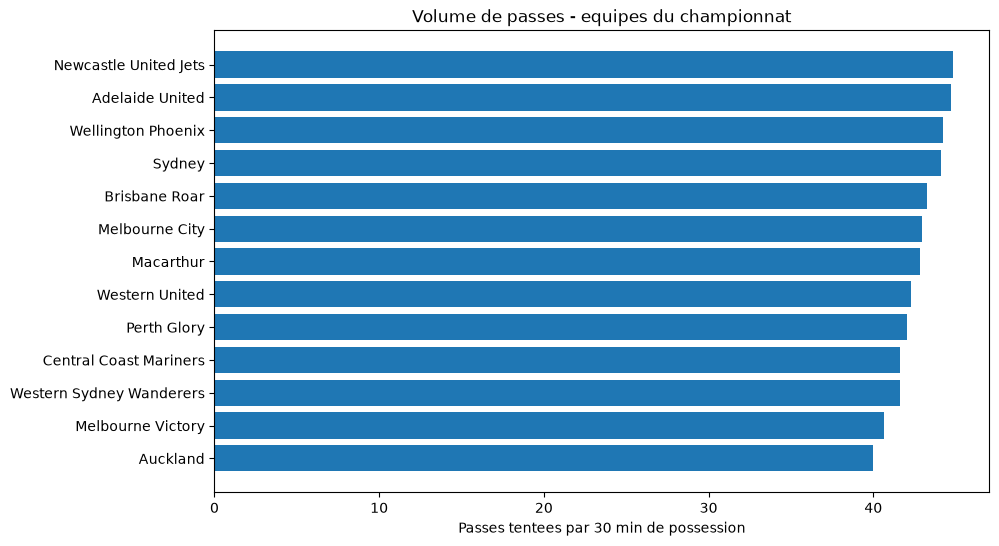

In [156]:
classement = equipes.sort_values('pass_count_attempted_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['pass_count_attempted_p30tip'])
plt.xlabel('Passes tentees par 30 min de possession')
plt.title('Volume de passes - equipes du championnat')


### Graphique — passes difficiles

Ce deuxième classement reprend exactement la même méthode de visualisation mais change l'indicateur sélectionné. La cohérence des unités par 30 minutes de possession facilite une comparaison séparée de ces deux dimensions du jeu.

Text(0.5, 1.0, 'Passes difficiles - equipes du championnat')

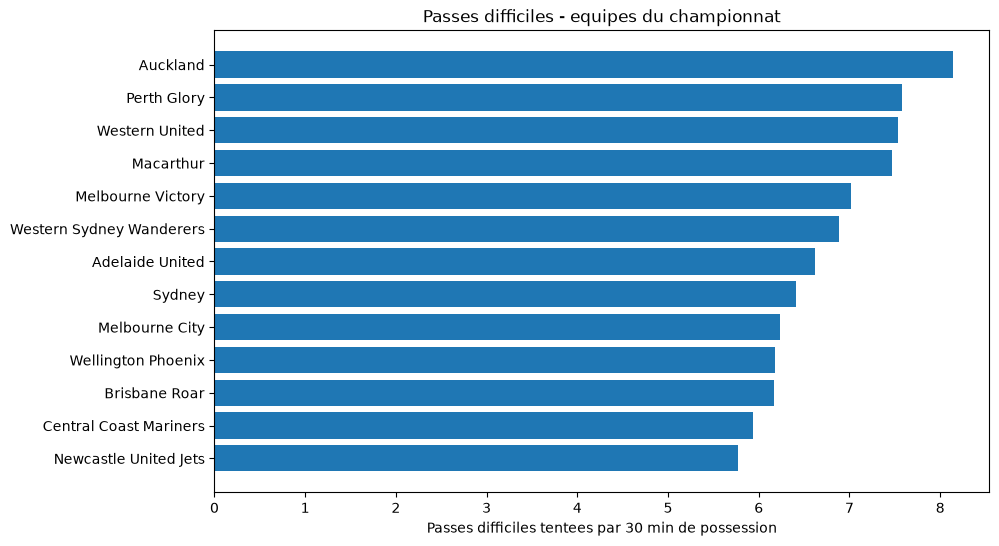

In [157]:
classement = equipes.sort_values('pass_count_difficultpass_attempted_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['pass_count_difficultpass_attempted_p30tip'])
plt.xlabel('Passes difficiles tentees par 30 min de possession')
plt.title('Passes difficiles - equipes du championnat')


### Graphique — volume de courses sans ballon

Le diagramme utilise `offballrun_count_p30tip`. On conserve la même unité que dans les tableaux des courses pour que la lecture du classement soit cohérente.

Text(0.5, 1.0, 'Volume de courses sans ballon - equipes du championnat')

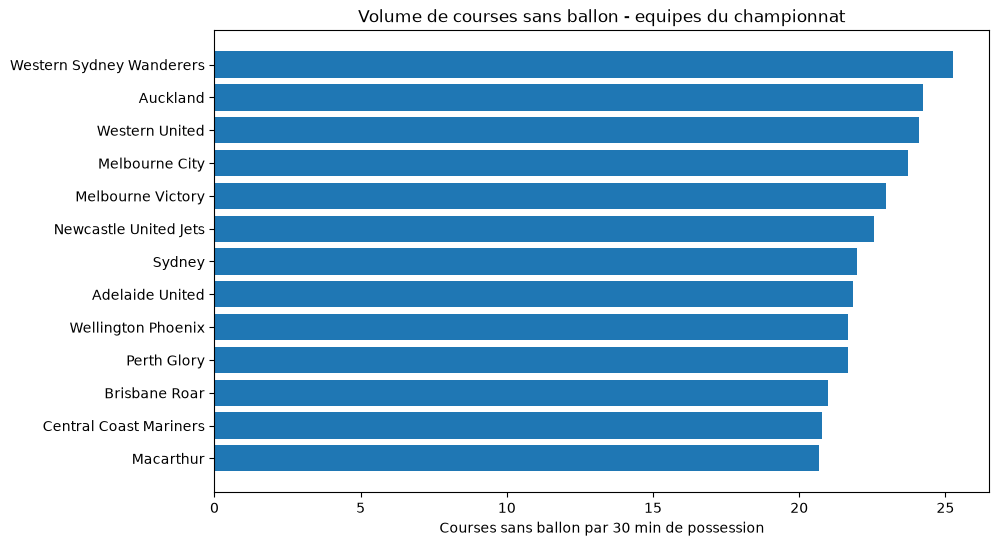

In [158]:
classement = equipes.sort_values('offballrun_count_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['offballrun_count_p30tip'])
plt.xlabel('Courses sans ballon par 30 min de possession')
plt.title('Volume de courses sans ballon - equipes du championnat')


### Graphique — relation entre passes et courses

On utilise `plt.scatter()` pour représenter simultanément deux indicateurs au niveau des équipes : passes tentées sur l'axe horizontal, courses sans ballon sur l'axe vertical. Un second appel à `plt.scatter()` colore la ligne d'Auckland en rouge, `plt.legend()` permet de lire la légende. Chaque point correspond à une équipe, et non à un joueur ou à un match.

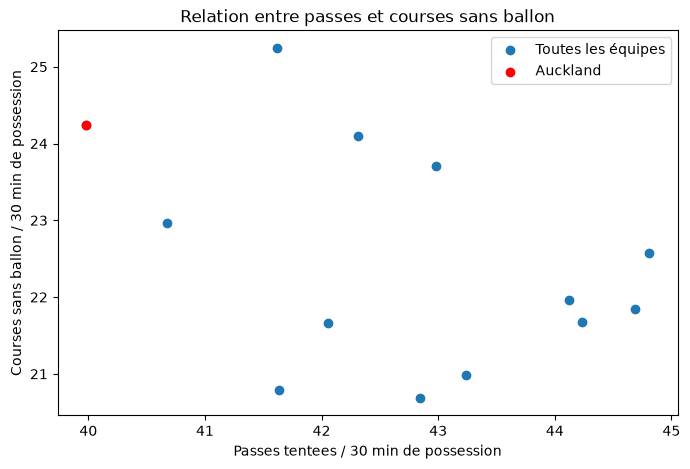

In [159]:
plt.figure(figsize=(8, 5))
plt.scatter(equipes['pass_count_attempted_p30tip'],
            equipes['offballrun_count_p30tip'],
            label='Toutes les équipes')
plt.scatter(auckland['pass_count_attempted_p30tip'],
            auckland['offballrun_count_p30tip'],
            color='red', label='Auckland')
plt.xlabel('Passes tentees / 30 min de possession')
plt.ylabel('Courses sans ballon / 30 min de possession')
plt.title('Relation entre passes et courses sans ballon')
plt.legend()

### Graphique — part des passes longues

La part des passes longues est une proportion calculée à partir de deux taux de passes (`passes longues / passes tentées`). Le graphique représente les valeurs décimales comprises entre 0 et 1.

Text(0.5, 1.0, 'Part des passes longues - equipes du championnat')

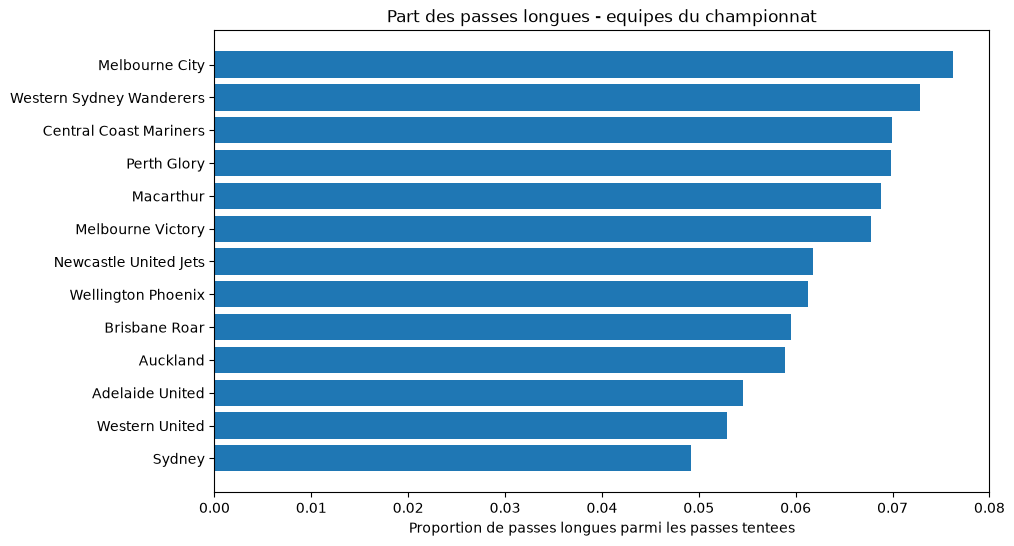

In [160]:
classement = equipes.sort_values('part_passes_longues')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['part_passes_longues'])
plt.xlabel('Proportion de passes longues parmi les passes tentees')
plt.title('Part des passes longues - equipes du championnat')


### Graphique — part des courses dans le dos

Cette part est calculée comme le rapport entre les courses identifiées « dans le dos de la défense » et l'ensemble des courses sans ballon. Comme pour les passes longues, les valeurs restent en proportions décimales dans le graphique.

Text(0.5, 1.0, 'Part des courses dans le dos de la defense - equipes du championnat')

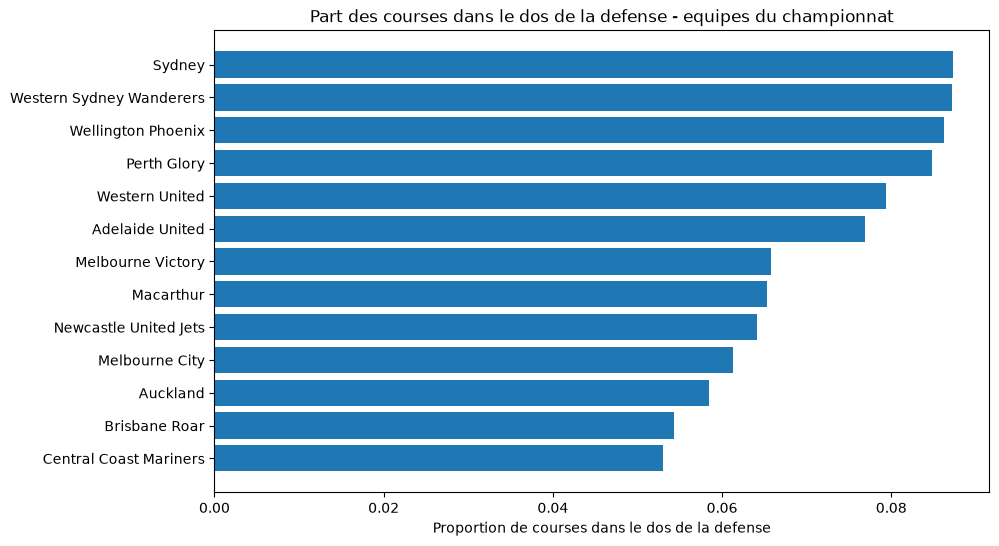

In [161]:
classement = equipes.sort_values('part_courses_dos_defense')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['part_courses_dos_defense'])
plt.xlabel('Proportion de courses dans le dos de la defense')
plt.title('Part des courses dans le dos de la defense - equipes du championnat')


Auckland est une des dernière équipe en termes de proportion de courses dans le dos de la défense, ce qui pourrait traduire un jeu moins direct que ce que l'on pense à cause des passes longues.

## 7. Récapitulatif méthodologique et profil saisonnier d'Auckland FC

Ce notebook transforme trois tables saisonnières de profils joueurs en tableaux descriptifs comparables entre équipes. Les principales étapes sont : filtrer les observations selon leur nombre de matchs, harmoniser les noms d'équipes, appliquer des moyennes pondérées adaptées aux familles de mesures, réunir les résultats avec `merge()`, construire des proportions et produire des tableaux et graphiques lisibles.

Sur la saison 2024-2025, Auckland se caractérise par un faible volume de passes (39,98 par 30 minutes de possession, contre 42,71 pour la ligue) mais par le plus grand nombre de passes difficiles tentées (8,14, contre 6,77). Son taux de passes réussies atteint 80,96 % et la réussite de ses passes cassant une ligne (69,79 %) reste inférieure à la moyenne du championnat (73,20 %).

Le jeu sans ballon constitue une autre caractéristique marquante : Auckland réalise 24,24 courses par 30 minutes de possession, soit le deuxième total de la ligue. Les courses de soutien (4,53) et vers les demi-espaces (0,96) sont particulièrement présentes, tandis que la part des courses dans le dos de la défense demeure relativement limitée (5,85 %).

Limite : ces statistiques collectives sont reconstituées à partir d'agrégats individuels saisonniers et dépendent du filtrage des joueurs et des pondérations retenues.

## 8. Complément : le classement final (Wikipédia)

Les données SkillCorner décrivent la manière de jouer des équipes, pas leurs résultats. On récupère donc le classement final de la saison régulière sur la page Wikipédia de l'A-League Men 2024-2025, par *scraping* avec `requests` et `pd.read_html()` (fonction `charger_classement()` de `src/donnees.py`). `read_html()` renvoie tous les tableaux de la page ; l'argument `match='Pld'` garde ceux qui ont une colonne de matchs joués, et le premier est le classement. Les noms d'équipes sont harmonisés avec ceux du tableau `equipes` (seul Newcastle s'écrit différemment), la mention « (C) » du champion est retirée et le signe « − » des différences de buts est remplacé avant la conversion en nombres. Si la page est inaccessible, on utilise une copie du tableau enregistrée dans `data/`. La jointure avec `merge(how='left')` garde les treize équipes du tableau `equipes`.

In [26]:
import sys
from pathlib import Path

#on indique le chemin du dossier src
if Path('src').exists():
    sys.path.append('src')
else:
    sys.path.append('../src')
from donnees import charger_classement

classement_final = charger_classement()
equipes_classement = equipes.merge(classement_final, on='equipe', how='left')
print('Équipes sans classement :', equipes_classement['points'].isna().sum())
equipes_classement[['equipe', 'rang_final', 'points', 'victoires', 'nuls', 'defaites']].sort_values('rang_final')

Classement récupéré sur Wikipédia
Équipes sans classement : 0


,equipe,rang_final,points,victoires,nuls,defaites
1,Auckland,1,53,15,8,3
5,Melbourne City,2,48,14,6,6
12,Western United,3,47,14,5,7
11,Western Sydney Wanderers,4,46,13,7,6
6,Melbourne Victory,5,43,12,7,7
0,Adelaide United,6,38,10,8,8
9,Sydney,7,37,10,7,9
4,Macarthur,8,33,9,6,11
7,Newcastle United Jets,9,30,8,6,12
3,Central Coast Mariners,10,26,5,11,10


On calcule avec `corrwith()` la corrélation entre quelques indicateurs de style et le nombre de points. Avec treize équipes, une seule équipe peut déplacer nettement ces coefficients : on les recalcule donc sans Auckland, qui occupe une position extrême sur plusieurs indicateurs. Une corrélation ne dit pas le sens de la relation : un style peut favoriser les résultats, mais une équipe qui mène au score peut aussi jouer différemment.

In [27]:
indicateurs = ['pass_count_attempted_p30tip', 'part_passes_difficiles', 'pass_count_dangerous_attempted_p30tip',
               'offballrun_count_p30tip', 'part_courses_dos_defense', 'offballrun_avgdistance', 'hsr_distance_full_all']
sans_auckland = equipes_classement[equipes_classement['equipe'] != 'Auckland']
correlations = pd.DataFrame({
    'corrélation avec les points': equipes_classement[indicateurs].corrwith(equipes_classement['points']),
    'sans Auckland': sans_auckland[indicateurs].corrwith(sans_auckland['points'])
})
correlations.rename(index=noms_variables).round(2)

,corrélation avec les points,sans Auckland
Passes tentées / 30 min,-0.40,-0.21
Part de passes difficiles,0.44,0.22
Passes dangereuses / 30 min,0.63,0.64
Courses / 30 min,0.80,0.77
Part de courses dans le dos,-0.02,0.13
Distance moyenne des courses (m),0.43,0.30
Distance à haute vitesse (unité SkillCorner),0.62,0.52


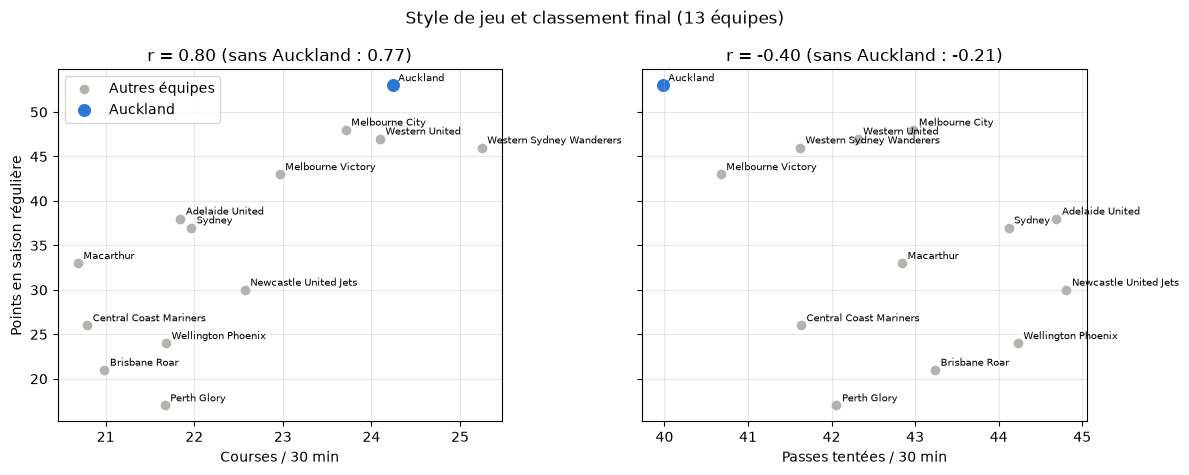

,equipe,offballrun_count_p30tip,rang_final
11,Western Sydney Wanderers,25.244043,4
1,Auckland,24.238766,1
12,Western United,24.095214,3
5,Melbourne City,23.709076,2


In [28]:
auckland = equipes_classement[equipes_classement['equipe'] == 'Auckland']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, variable in zip(axes, ['offballrun_count_p30tip', 'pass_count_attempted_p30tip']):
    ax.scatter(sans_auckland[variable], sans_auckland['points'], color='#b5b3ad', label='Autres équipes')
    ax.scatter(auckland[variable], auckland['points'], color='#2a78d6', s=70, label='Auckland')
    for _, ligne in equipes_classement.iterrows():
        ax.annotate(ligne['equipe'], (ligne[variable], ligne['points']), xytext=(4, 3),
                    textcoords='offset points', fontsize=7)
    r = correlations.loc[variable, 'corrélation avec les points']
    r_sans = correlations.loc[variable, 'sans Auckland']
    ax.set_title(f'r = {r:.2f} (sans Auckland : {r_sans:.2f})')
    ax.set_xlabel(noms_variables[variable])
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Points en saison régulière')
axes[0].legend()
fig.suptitle('Style de jeu et classement final (13 équipes)')
plt.tight_layout()
dossier_images = Path('images') if Path('images').exists() else Path('../images')
plt.savefig(dossier_images / 'style_et_points.png', dpi=120, bbox_inches='tight')
plt.show()

#les quatre équipes qui font le plus de courses sans ballon
equipes_classement.nlargest(4, 'offballrun_count_p30tip')[['equipe', 'offballrun_count_p30tip', 'rang_final']]